<h5>Conditional Routing with More Nodes

class State(TypedDict):
-------messages: Annotated [list, add_messages]
-------topic: str

messages is a list. Each item in that list is typically a LangChain message object, like:

HumanMessage
AIMessage So internally, it looks something like:
state = {
"messages": [
HumanMessage(content="Explain AI agents"),
AIMessage(content="Sure...")
],
"topic": ""
}
state['messages'][0] meand like HumanMessage(content="Explain AI agents")</h5>

In [4]:
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from IPython.display import display, Image

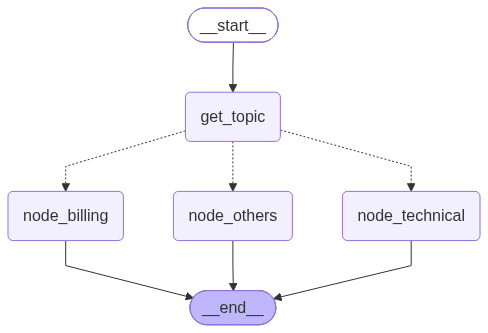

In [12]:
class State(TypedDict):
   messages: Annotated[list[str], add_messages]
   topic: str

# Extract human input and that will be sentiment
def get_topic(state: State) -> str:
    print("State: ", state)
#     state = {
#     "messages": [
#         HumanMessage(content="finance")
#     ]
# }
    # Extract the topic from the messages
    topic = state['messages'][0].content
    print(f"---Getting topic: {topic}---")
    return {"topic": topic}

def decide_route(state: State) -> State:
    print("---Conditional Routing---")
#     {
#     "messages": [
#         HumanMessage(content="finance")
#     ],
#     "topic": "finance"
# }
    topic = state['topic']
    print(topic)
    if topic.lower() in ['billing', 'finance']:
        return "node_billing"
    if topic.lower() in ['technical', 'coding']:
        return "node_technical"
    return "node_others"

def billing(state):
    print("---Node billing---")
    topic = state['topic']
    return {"messages": "Happy to help your query related to : "+topic}

def technical(state):
    print("---technical---")
    topic = state['topic']
    return {"messages": "Happy to help your query related to: "+topic}

def others(state):
    print("---Node Others---")
    topic = state['topic']
    return {"messages": "Sorry we do not have: "+topic}

# Build graph
builder = StateGraph(State)
builder.add_node("get_topic", get_topic)
builder.add_node("node_billing", billing)
builder.add_node("node_technical", technical)
builder.add_node("node_others", others)

# Logic
builder.add_edge(START, "get_topic")
builder.add_conditional_edges("get_topic",
                              decide_route,
                              ["node_billing", "node_technical", "node_others"]
                              )
builder.add_edge("node_billing", END)
builder.add_edge("node_technical", END)
builder.add_edge("node_others", END)
# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
def call_agent(agent, topic):
    msgs  = agent.invoke({"messages": topic})
    print(msgs)
    print(msgs['messages'][-1].content)

In [14]:
call_agent(graph, "Billing")

State:  {'messages': [HumanMessage(content='Billing', additional_kwargs={}, response_metadata={}, id='b2ded8ad-f878-408a-9d6b-f4d605048fce')]}
---Getting topic: Billing---
---Conditional Routing---
Billing
---Node billing---
{'messages': [HumanMessage(content='Billing', additional_kwargs={}, response_metadata={}, id='b2ded8ad-f878-408a-9d6b-f4d605048fce'), HumanMessage(content='Happy to help your query related to : Billing', additional_kwargs={}, response_metadata={}, id='9a705d9d-6844-4c0b-a552-215f21b64776')], 'topic': 'Billing'}
Happy to help your query related to : Billing
